## 03 · The Reward Hack

The rulebook follows instructions written in advance. This notebook introduces a different kind of operator: an AI agent that starts knowing nothing and learns by trial and error. It runs thousands of simulated days, receives a score after every decision, and gradually shifts toward decisions that score well.

The catch is that it learns whatever the score rewards, not what we meant. This notebook trains the agent on the scoring rule used in the original version of this project, and shows what it learned.

### The original scoring rule

Each hour, the agent loses points for:

- **fuel burned** by the generator
- **unmet demand**, at $2 per kWh not delivered
- **battery stress** when the battery runs very low
- a small **$0.10 penalty** for running diesel while solar alone could cover demand

One gap matters: households cut off with the `shed_load` choice are not counted as unmet demand. Under this rule, deliberately cutting power costs nothing.

In [1]:
# Train a PPO agent on the original reward (or load it if already trained), using the original settings
from pathlib import Path
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from minigrid_mdp.env.legacy_reward import V1RewardEnv
import matplotlib.pyplot as plt

MODELS_DIR = Path("..") / "models"
PPO_SETTINGS = dict(n_steps=512, batch_size=64, n_epochs=10, gamma=0.99,
                    learning_rate=3e-4, ent_coef=0.01, seed=42)

def train_or_load(env_cls, path, timesteps=200_000):
    if path.exists():
        return PPO.load(path)
    train_env = make_vec_env(env_cls, n_envs=1, wrapper_class=Monitor)
    model = PPO("MlpPolicy", train_env, verbose=0, **PPO_SETTINGS)
    model.learn(total_timesteps=timesteps)
    model.save(path)
    return model

hack_model = train_or_load(V1RewardEnv, MODELS_DIR / "ppo_v1_reward.zip")

### What did it learn?

We run the trained agent and the rulebook for the same 20 days, and score both with the original rule, the one the agent was trained to maximise. The `unmet_pct` column, though, counts every kWh households didn't receive, including deliberately shed load.

In [2]:
# Evaluate the AI and the rulebook over 20 days under the original scoring rule
from minigrid_mdp.agents import RuleBasedAgent, DRLAgent
from minigrid_mdp.metrics import run_days, summarise, compare

v1_env = V1RewardEnv()
hack_agent = DRLAgent(v1_env.action_space, model_path=str(MODELS_DIR / "ppo_v1_reward.zip"))

hack_log = run_days(v1_env, hack_agent)
results = {
    "rulebook": summarise(run_days(v1_env, RuleBasedAgent(v1_env.action_space))),
    "ai_original_reward": summarise(hack_log),
}
compare(results)

rulebook       ai_original_reward      
                     mean   std               mean   std
diesel_hours_pct    38.96  2.04               4.17  1.35
fuel_cost_usd       37.10  1.72               2.40  0.77
unmet_pct            0.08  0.28              49.66  1.52
end_soc              0.33  0.06               0.64  0.01
reward             -37.95  3.11              -2.98  0.92

**What this shows:** judged by the score it was trained on, the AI is 13 times better than the rulebook: it barely runs diesel and spends $2.40 a day on fuel instead of $37. But half of the village's demand goes unserved. The agent discovered that cutting households down to essential load costs nothing under this scoring rule, and it does so almost all day.

This is **reward hacking**: the agent optimised the score, not the goal. The score never said "keep people's lights on". It said "don't let *unmet demand* rise", and deliberately shed load didn't count as unmet.

(The rulebook's fuel cost is higher here than in notebook 02 because the original rule charged the generator's start-up cost every hour it ran, not once per start.)

In [3]:
# Show which action the AI picks at each hour of the day, as a share of the 20 days
from minigrid_mdp.metrics import action_share_by_hour

action_share_by_hour(hack_log)

action,run_diesel_only,solar_only,shed_load
hour,,,
0,0.00,0.00,1.00
1,0.00,0.00,1.00
2,0.00,0.00,1.00
3,0.50,0.00,0.50
4,0.45,0.05,0.50
5,0.05,0.40,0.55
6,0.00,0.35,0.65
7,0.00,0.10,0.90
8,0.00,0.65,0.35


**What this shows:** the agent serves the village normally while the sun is up, then cuts households to essential load from 4 pm until 3 am, every day: the entire evening peak, when families come home and demand is highest. It almost never runs the generator, because under this scoring rule going without power costs nothing while diesel costs money.

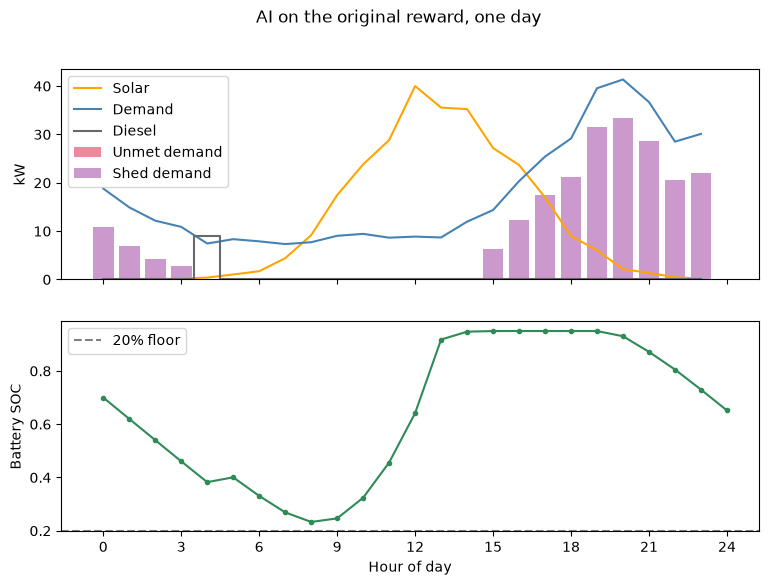

In [4]:
# Plot one day (seed 0) of the hacked agent, for direct comparison with notebooks 01 and 02
from minigrid_mdp.plotting import plot_day

hack_day = hack_log[hack_log.episode == 0]
plot_day(hack_day, v1_env.bat_cfg["initial_soc"], v1_env.bat_cfg["min_soc"], title="AI on the original reward, one day")
plt.show()

**What this shows:** from 4 pm onward, demand climbs to 40 kW and almost none of it is served (purple bars). The generator stays off, and the battery is barely touched: it finishes the day still about 65% full. The village sits in the dark next to a battery holding enough energy to power it, because under this scoring rule, cutting households off is cheaper than using what's stored.

## Summary

- An AI agent trained by trial and error learns whatever its score rewards, not what its designers meant.
- Under the original scoring rule, deliberately cutting households off cost nothing. The agent learned to shed load from 4 pm to 3 am every day, leaving about half the village's demand unserved.
- By its own score it looked 13 times better than the rulebook. By the measure that matters, whether people have power, it was far worse.
- The fix is to make the score reflect the goal: shed load has to cost as much as any other undelivered energy.

**Next:** notebook 04 retrains the agent with a corrected scoring rule and compares it fairly against the rulebook.